In [68]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt 
import pygmt
import harmonica as hm 
import bordado as bd 
import boule as bl
import verde as vd
import ensaio
import pyproj

In [69]:
caminho_grav = ensaio.fetch_southern_africa_gravity(version=1)

In [70]:
dado = pd.read_csv(caminho_grav)
dado

,longitude,latitude,height_sea_level_m,gravity_mgal
0,18.34444,-34.12971,32.2,979656.12
1,18.36028,-34.08833,592.5,979508.21
2,18.37418,-34.19583,18.4,979666.46
3,18.40388,-34.23972,25.0,979671.03
4,18.41112,-34.16444,228.7,979616.11
...,...,...,...,...
14354,21.22500,-17.95833,1053.1,978182.09
14355,21.27500,-17.98333,1033.3,978183.09
14356,21.70833,-17.99166,1041.8,978182.69
14357,21.85000,-17.95833,1033.3,978193.18


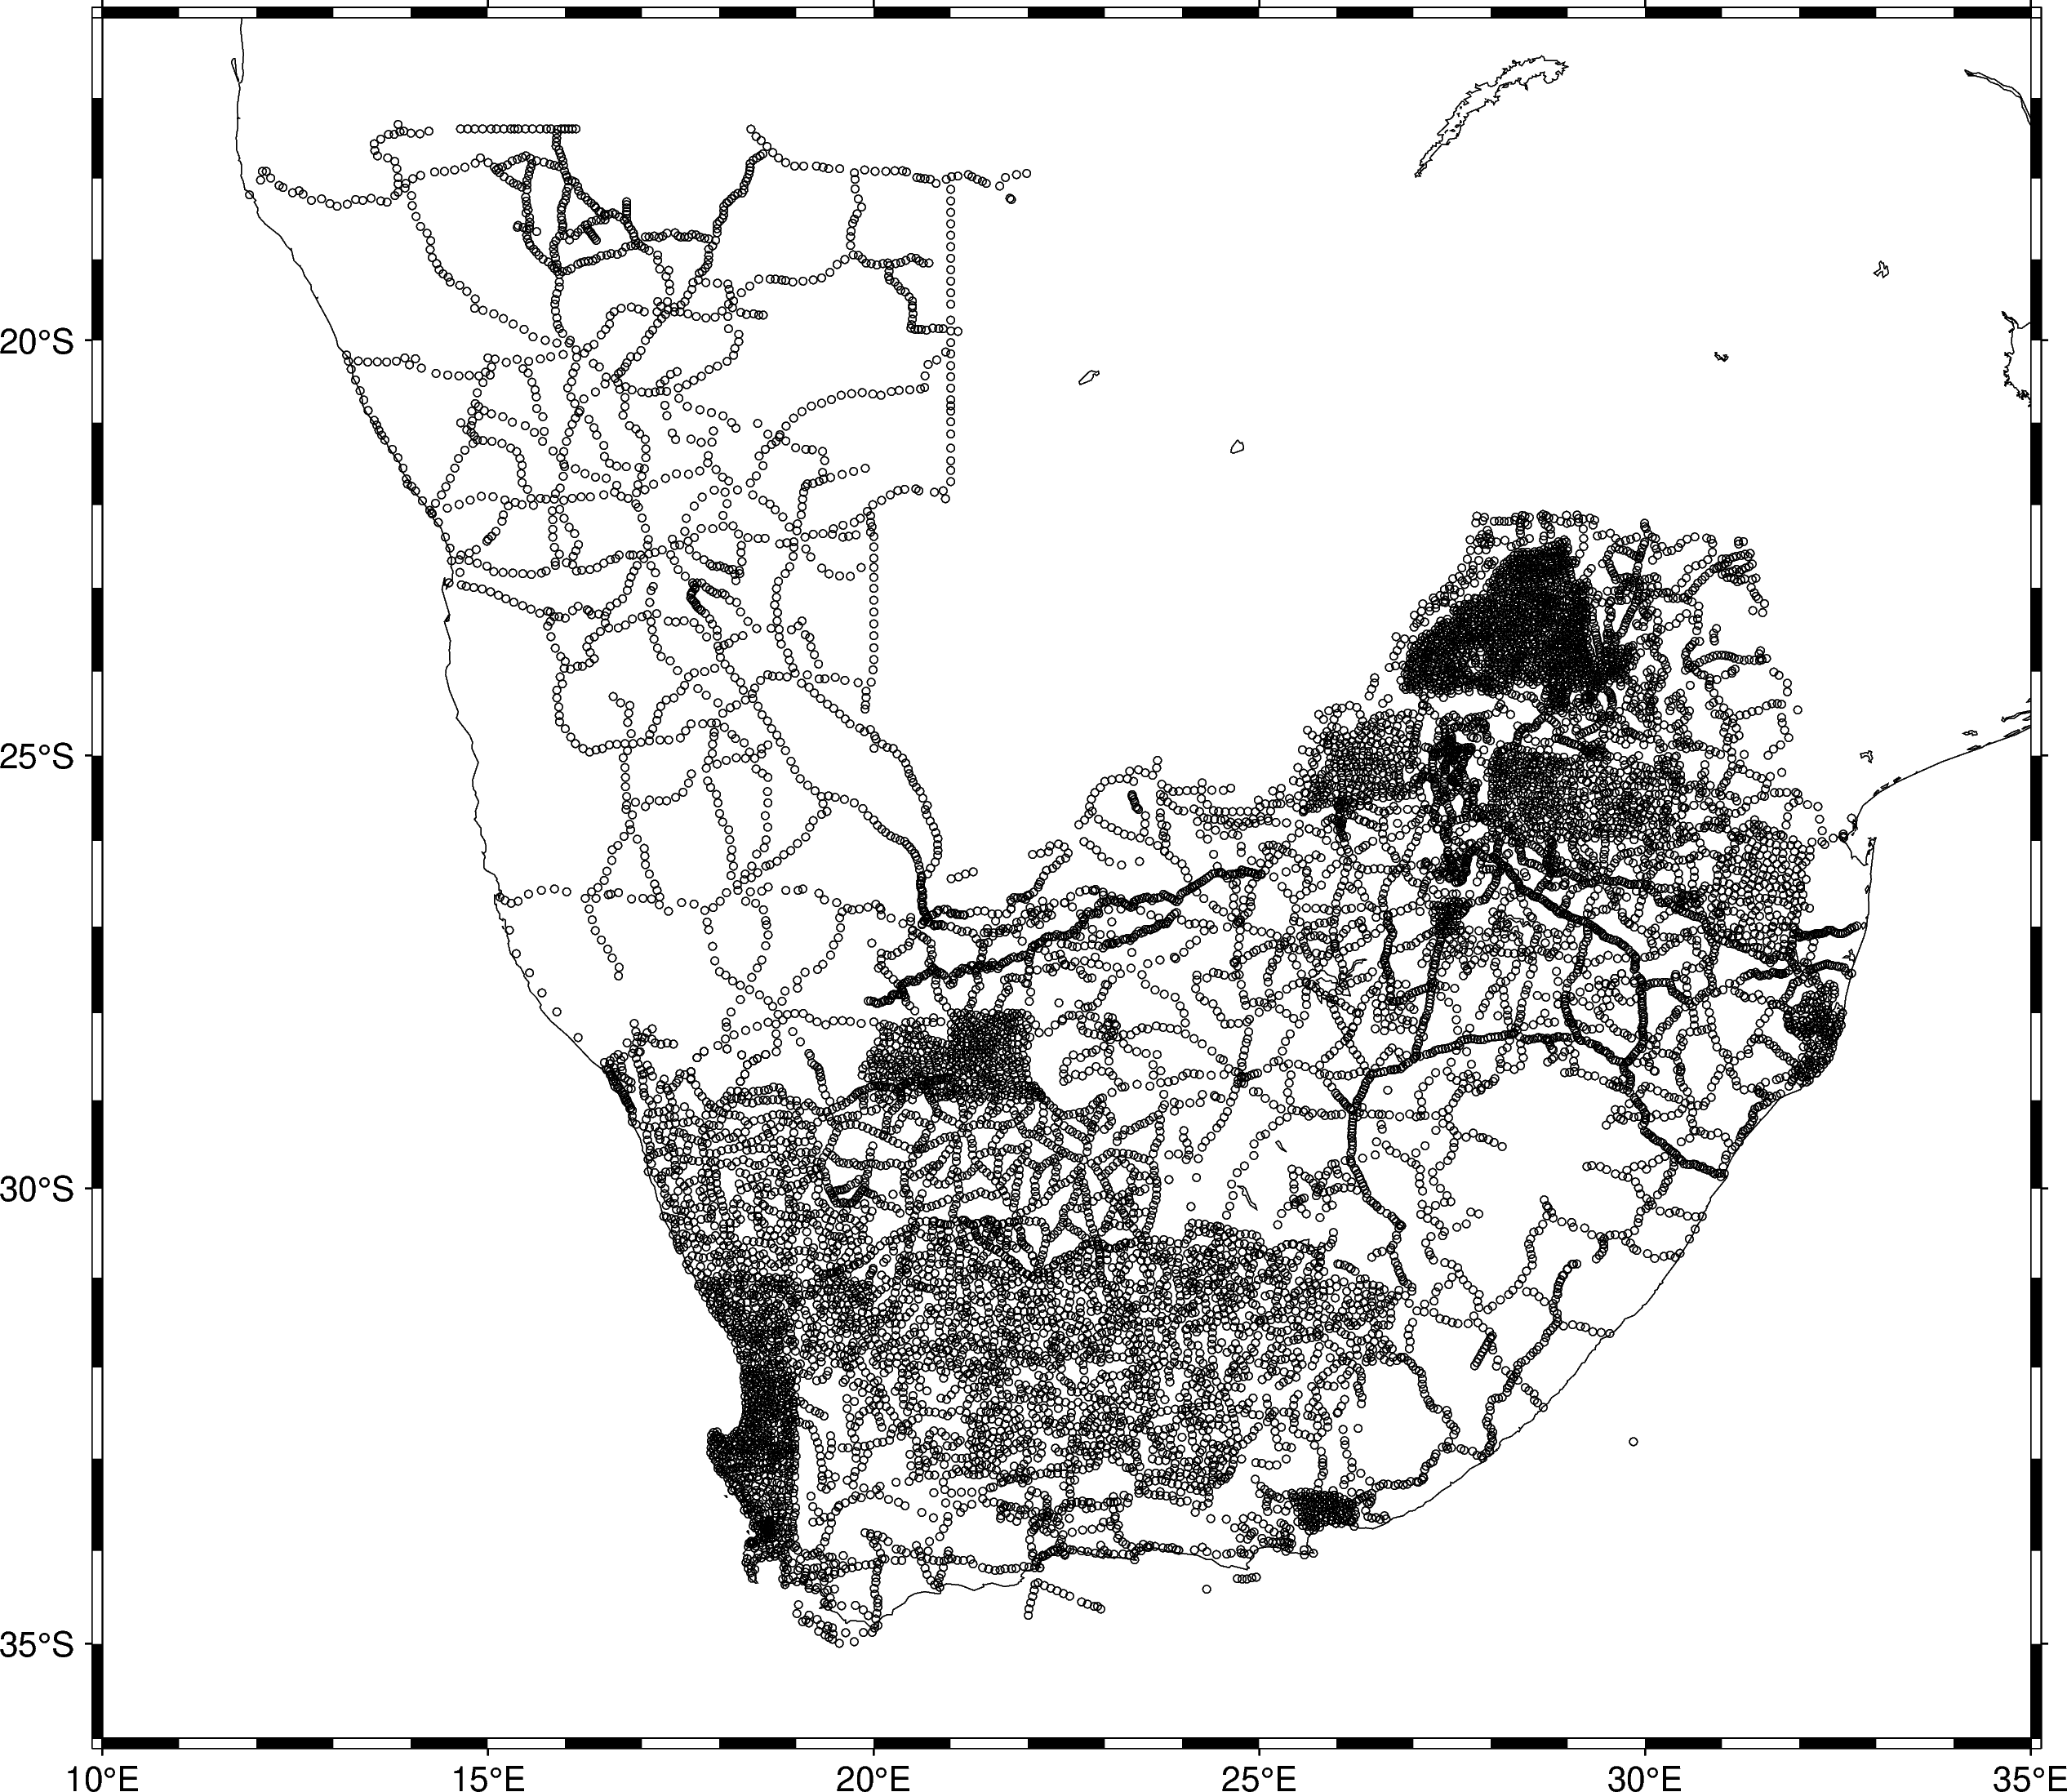

In [71]:
fig = pygmt.Figure()
fig.plot(x=dado.longitude, y=dado.latitude, style='c0.08c', projection="M20c")
fig.coast(shorelines=True, frame=True)
fig.show(width=1000)

In [72]:
regiao = (25, 32, -27, -23)
bushveld = bd.inside((dado.longitude, dado.latitude), regiao)
dado = dado[bushveld]

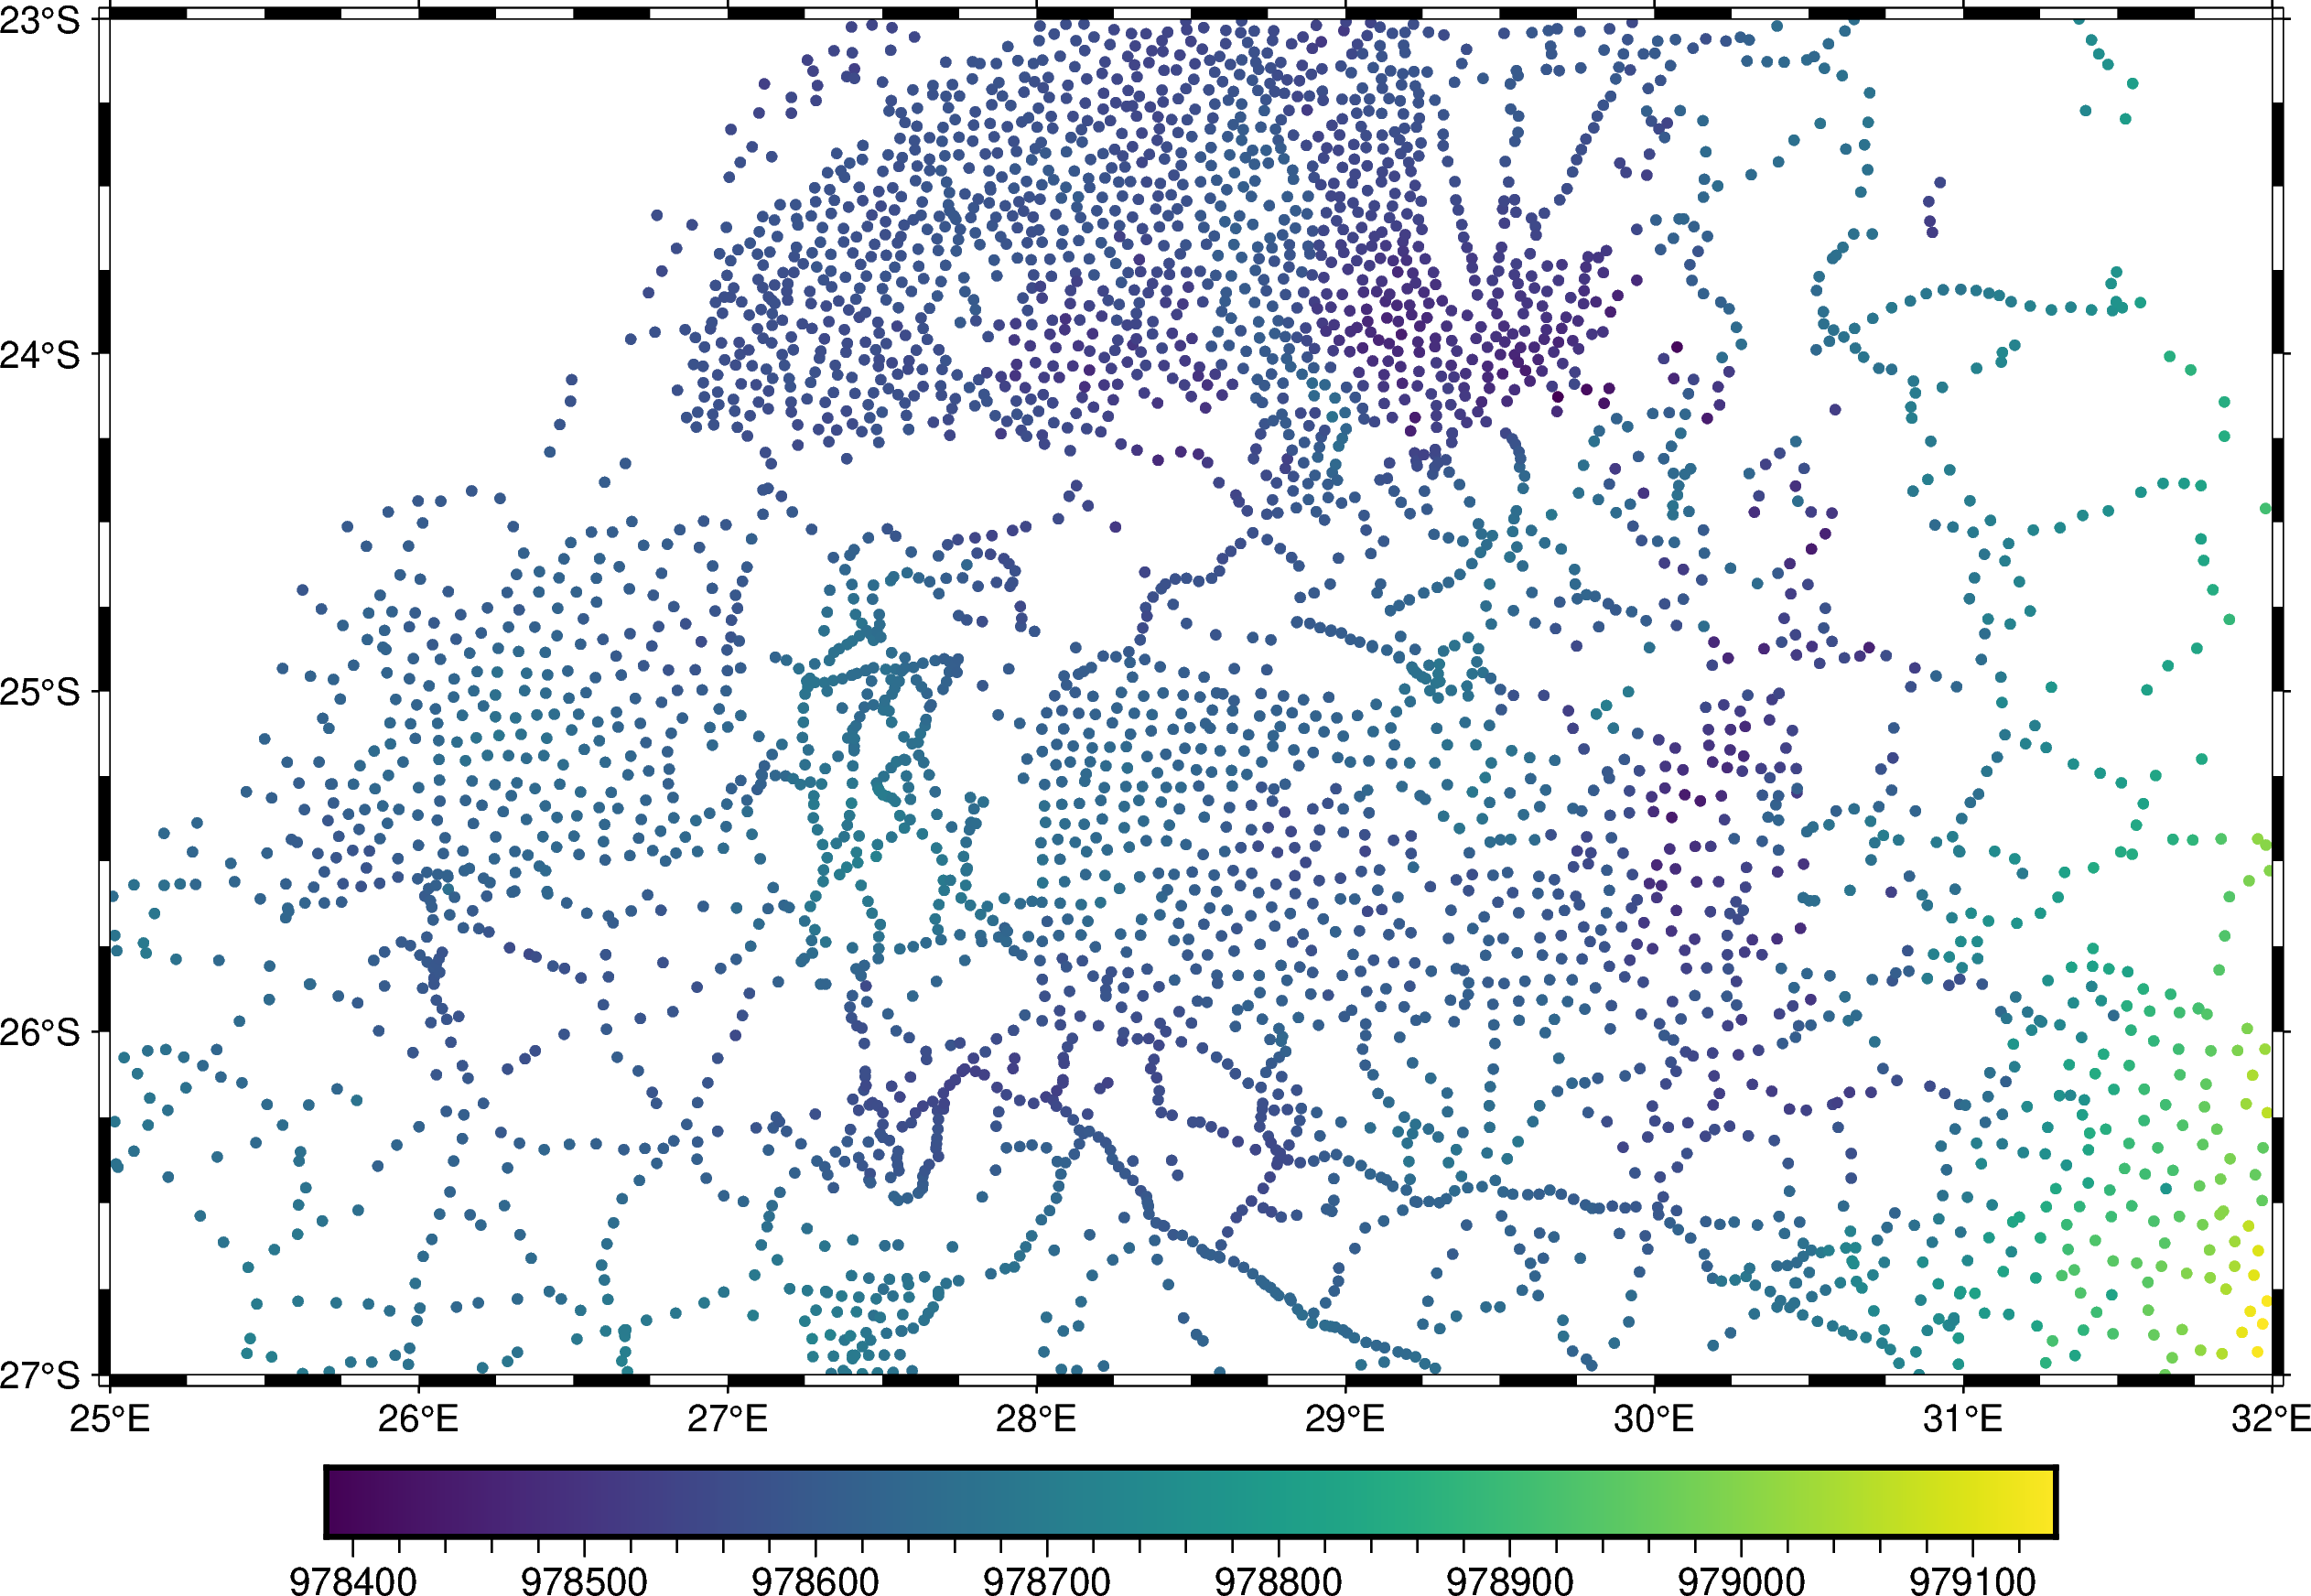

In [73]:
fig = pygmt.Figure()
pygmt.makecpt(cmap='viridis', series=[dado.gravity_mgal.min(), dado.gravity_mgal.max()],)
fig.plot(
    x=dado.longitude,
    y=dado.latitude,
    fill=dado.gravity_mgal,
    style='c0.1c',
    projection="M20c",
    cmap=True,
    frame=True
)
fig.colorbar(frame=True)
fig.show(width=1000)

In [74]:
caminho_geoide = ensaio.fetch_earth_geoid(version=1)
geoide = xr.load_dataarray(caminho_geoide)
geoide

<xarray.DataArray 'geoid' (latitude: 1081, longitude: 2161)> Size: 19MB
array([[-29.5, -29.5, -29.5, ..., -29.5, -29.5, -29.5],
       [-29.5, -29.5, -29.5, ..., -29.5, -29.5, -29.5],
       [-29.6, -29.6, -29.6, ..., -29.6, -29.6, -29.6],
       ...,
       [ 14.7,  14.7,  14.7, ...,  14.7,  14.7,  14.7],
       [ 15.2,  15.2,  15.2, ...,  15.2,  15.2,  15.2],
       [ 15.4,  15.4,  15.4, ...,  15.4,  15.4,  15.4]],
      shape=(1081, 2161))
Coordinates:
  * latitude   (latitude) float64 9kB -90.0 -89.83 -89.67 ... 89.67 89.83 90.0
  * longitude  (longitude) float64 17kB -180.0 -179.8 -179.7 ... 179.8 180.0
Attributes:
    Conventions:     CF-1.8
    title:           Geoid height (EIGEN-6C4) with respect to WGS84
    crs:             WGS84
    source:          Generated from the EIGEN-6C4 model by the ICGEM Calculat...
    license:         Creative Commons Attribution 4.0 International Licence
    references:      https://doi.org/10.5880/icgem.2015.1
    long_name:       geoid height
    standard_name:   geoid_height_above_reference_ellipsoid
    description:     height of the geoid with respect to the WGS84 ellipsoid
    units:           m
    actual_range:    [-106.5   86. ]
    icgem_metadata:  generating_institute: gfz-potsdam\ngenerating_date: 2021...

In [75]:
geoide_tabela = vd.grid_to_table(geoide)

In [76]:
interp = vd.KNeighbors(k=5).fit((geoide_tabela.longitude, geoide_tabela.latitude), geoide_tabela.geoid)
dado['geoide_m'] = interp.predict((dado.longitude, dado.latitude))
dado

,longitude,latitude,height_sea_level_m,gravity_mgal,geoide_m
8648,25.01500,-26.26334,1230.2,978681.38,27.44
8649,25.01932,-26.38713,1297.0,978669.02,27.84
8650,25.02499,-26.39667,1304.8,978669.28,27.84
8651,25.04500,-26.07668,1165.2,978681.08,26.96
8652,25.07668,-26.35001,1262.5,978665.19,27.74
...,...,...,...,...,...
12974,31.51500,-23.86333,300.5,978776.85,12.22
12975,31.52499,-23.30000,280.7,978798.55,11.88
12976,31.54832,-23.19333,245.7,978803.55,11.88
12977,31.57333,-23.84833,226.8,978808.44,12.54


In [77]:
dado['altura_geometrica_m'] = dado.geoide_m + dado.height_sea_level_m
dado

,longitude,latitude,height_sea_level_m,gravity_mgal,geoide_m,altura_geometrica_m
8648,25.01500,-26.26334,1230.2,978681.38,27.44,1257.64
8649,25.01932,-26.38713,1297.0,978669.02,27.84,1324.84
8650,25.02499,-26.39667,1304.8,978669.28,27.84,1332.64
8651,25.04500,-26.07668,1165.2,978681.08,26.96,1192.16
8652,25.07668,-26.35001,1262.5,978665.19,27.74,1290.24
...,...,...,...,...,...,...
12974,31.51500,-23.86333,300.5,978776.85,12.22,312.72
12975,31.52499,-23.30000,280.7,978798.55,11.88,292.58
12976,31.54832,-23.19333,245.7,978803.55,11.88,257.58
12977,31.57333,-23.84833,226.8,978808.44,12.54,239.34


In [78]:
dado['gravidade_normal_mgal'] = bl.WGS84.normal_gravity((dado.longitude, dado.latitude, dado.altura_geometrica_m))
dado

,longitude,latitude,height_sea_level_m,gravity_mgal,geoide_m,altura_geometrica_m,gravidade_normal_mgal
8648,25.01500,-26.26334,1230.2,978681.38,27.44,1257.64,978656.247360
8649,25.01932,-26.38713,1297.0,978669.02,27.84,1324.84,978644.399827
8650,25.02499,-26.39667,1304.8,978669.28,27.84,1332.64,978642.679408
8651,25.04500,-26.07668,1165.2,978681.08,26.96,1192.16,978663.108880
8652,25.07668,-26.35001,1262.5,978665.19,27.74,1290.24,978652.406949
...,...,...,...,...,...,...,...
12974,31.51500,-23.86333,300.5,978776.85,12.22,312.72,978781.630953
12975,31.52499,-23.30000,280.7,978798.55,11.88,292.58,978750.570147
12976,31.54832,-23.19333,245.7,978803.55,11.88,257.58,978754.392140
12977,31.57333,-23.84833,226.8,978808.44,12.54,239.34,978803.279593


In [79]:
dado["disturbio_mgal"] = dado.gravity_mgal - dado.gravidade_normal_mgal
dado

,longitude,latitude,height_sea_level_m,gravity_mgal,geoide_m,altura_geometrica_m,gravidade_normal_mgal,disturbio_mgal
8648,25.01500,-26.26334,1230.2,978681.38,27.44,1257.64,978656.247360,25.132640
8649,25.01932,-26.38713,1297.0,978669.02,27.84,1324.84,978644.399827,24.620173
8650,25.02499,-26.39667,1304.8,978669.28,27.84,1332.64,978642.679408,26.600592
8651,25.04500,-26.07668,1165.2,978681.08,26.96,1192.16,978663.108880,17.971120
8652,25.07668,-26.35001,1262.5,978665.19,27.74,1290.24,978652.406949,12.783051
...,...,...,...,...,...,...,...,...
12974,31.51500,-23.86333,300.5,978776.85,12.22,312.72,978781.630953,-4.780953
12975,31.52499,-23.30000,280.7,978798.55,11.88,292.58,978750.570147,47.979853
12976,31.54832,-23.19333,245.7,978803.55,11.88,257.58,978754.392140,49.157860
12977,31.57333,-23.84833,226.8,978808.44,12.54,239.34,978803.279593,5.160407


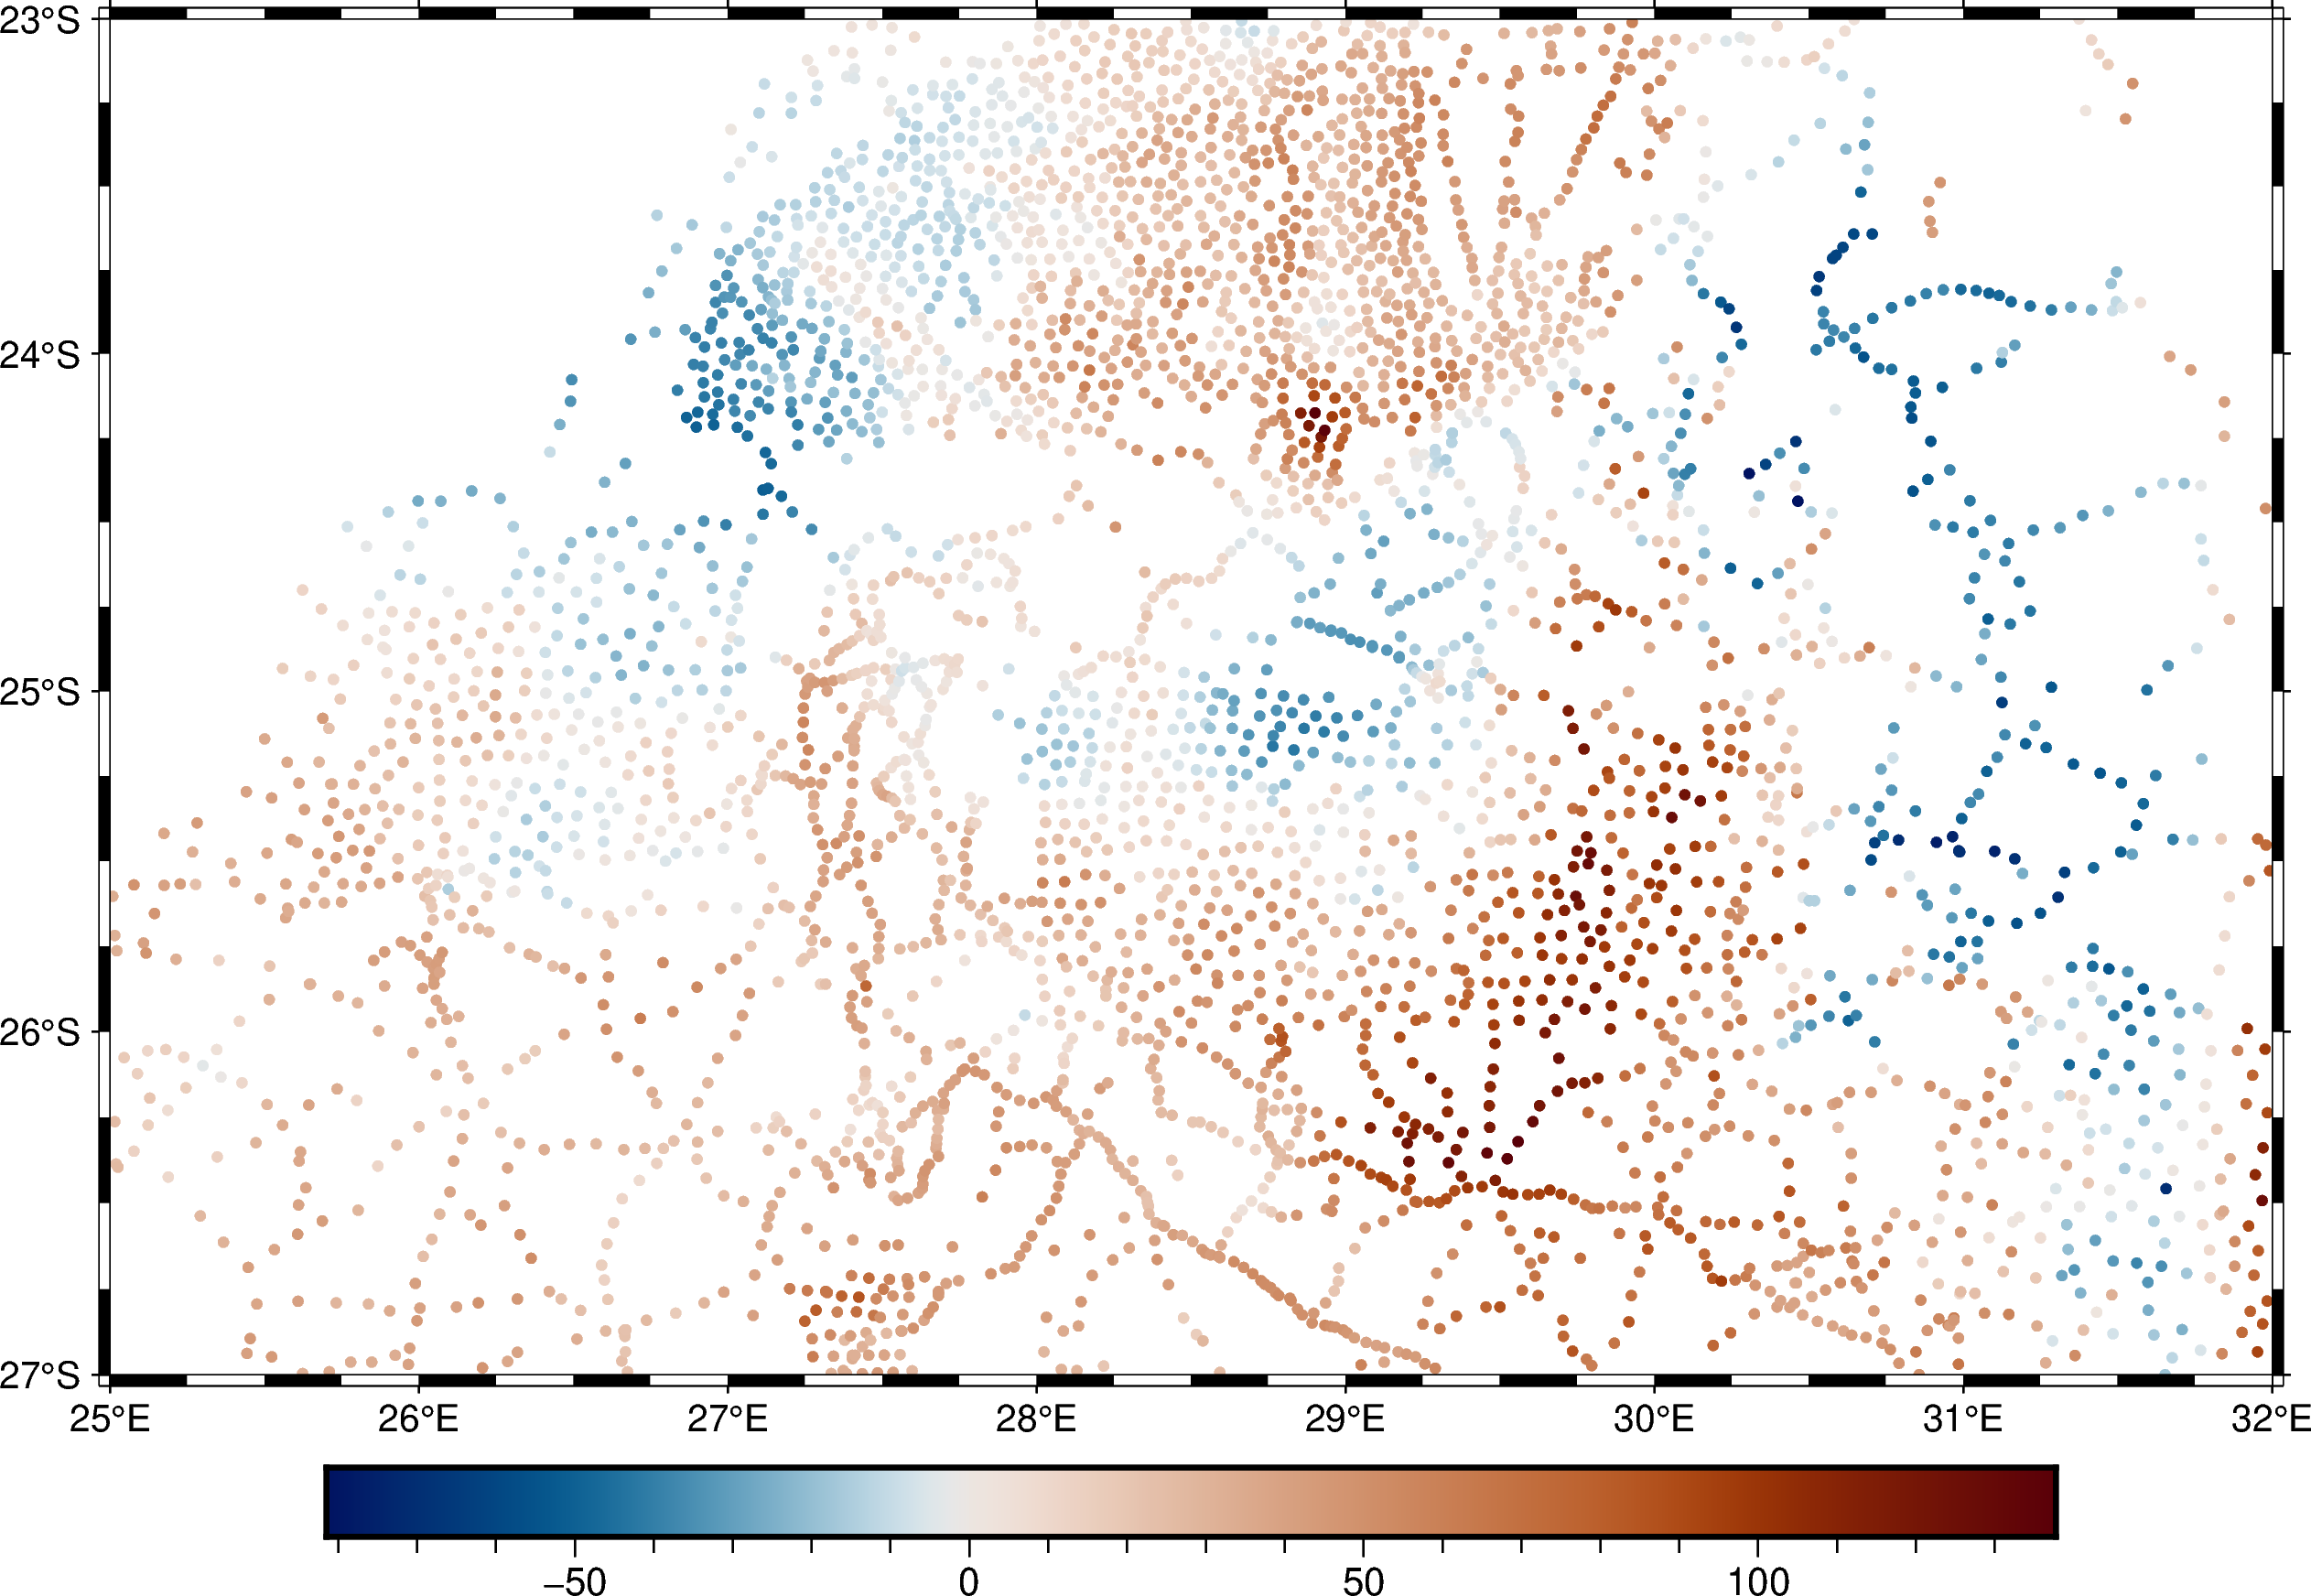

In [80]:
fig = pygmt.Figure()
pygmt.makecpt(cmap='vik+h', series=[dado.disturbio_mgal.min(), dado.disturbio_mgal.max()],)
fig.plot(
    x=dado.longitude,
    y=dado.latitude,
    fill=dado.disturbio_mgal,
    style='c0.1c',
    projection="M20c",
    cmap=True,
    frame=True
)
fig.colorbar(frame=True)
fig.show(width=1000)

In [81]:
dado["disturbio_bouguer_mgal"] = (
    dado.disturbio_mgal
    - hm.bouguer_correction(dado.altura_geometrica_m)
)

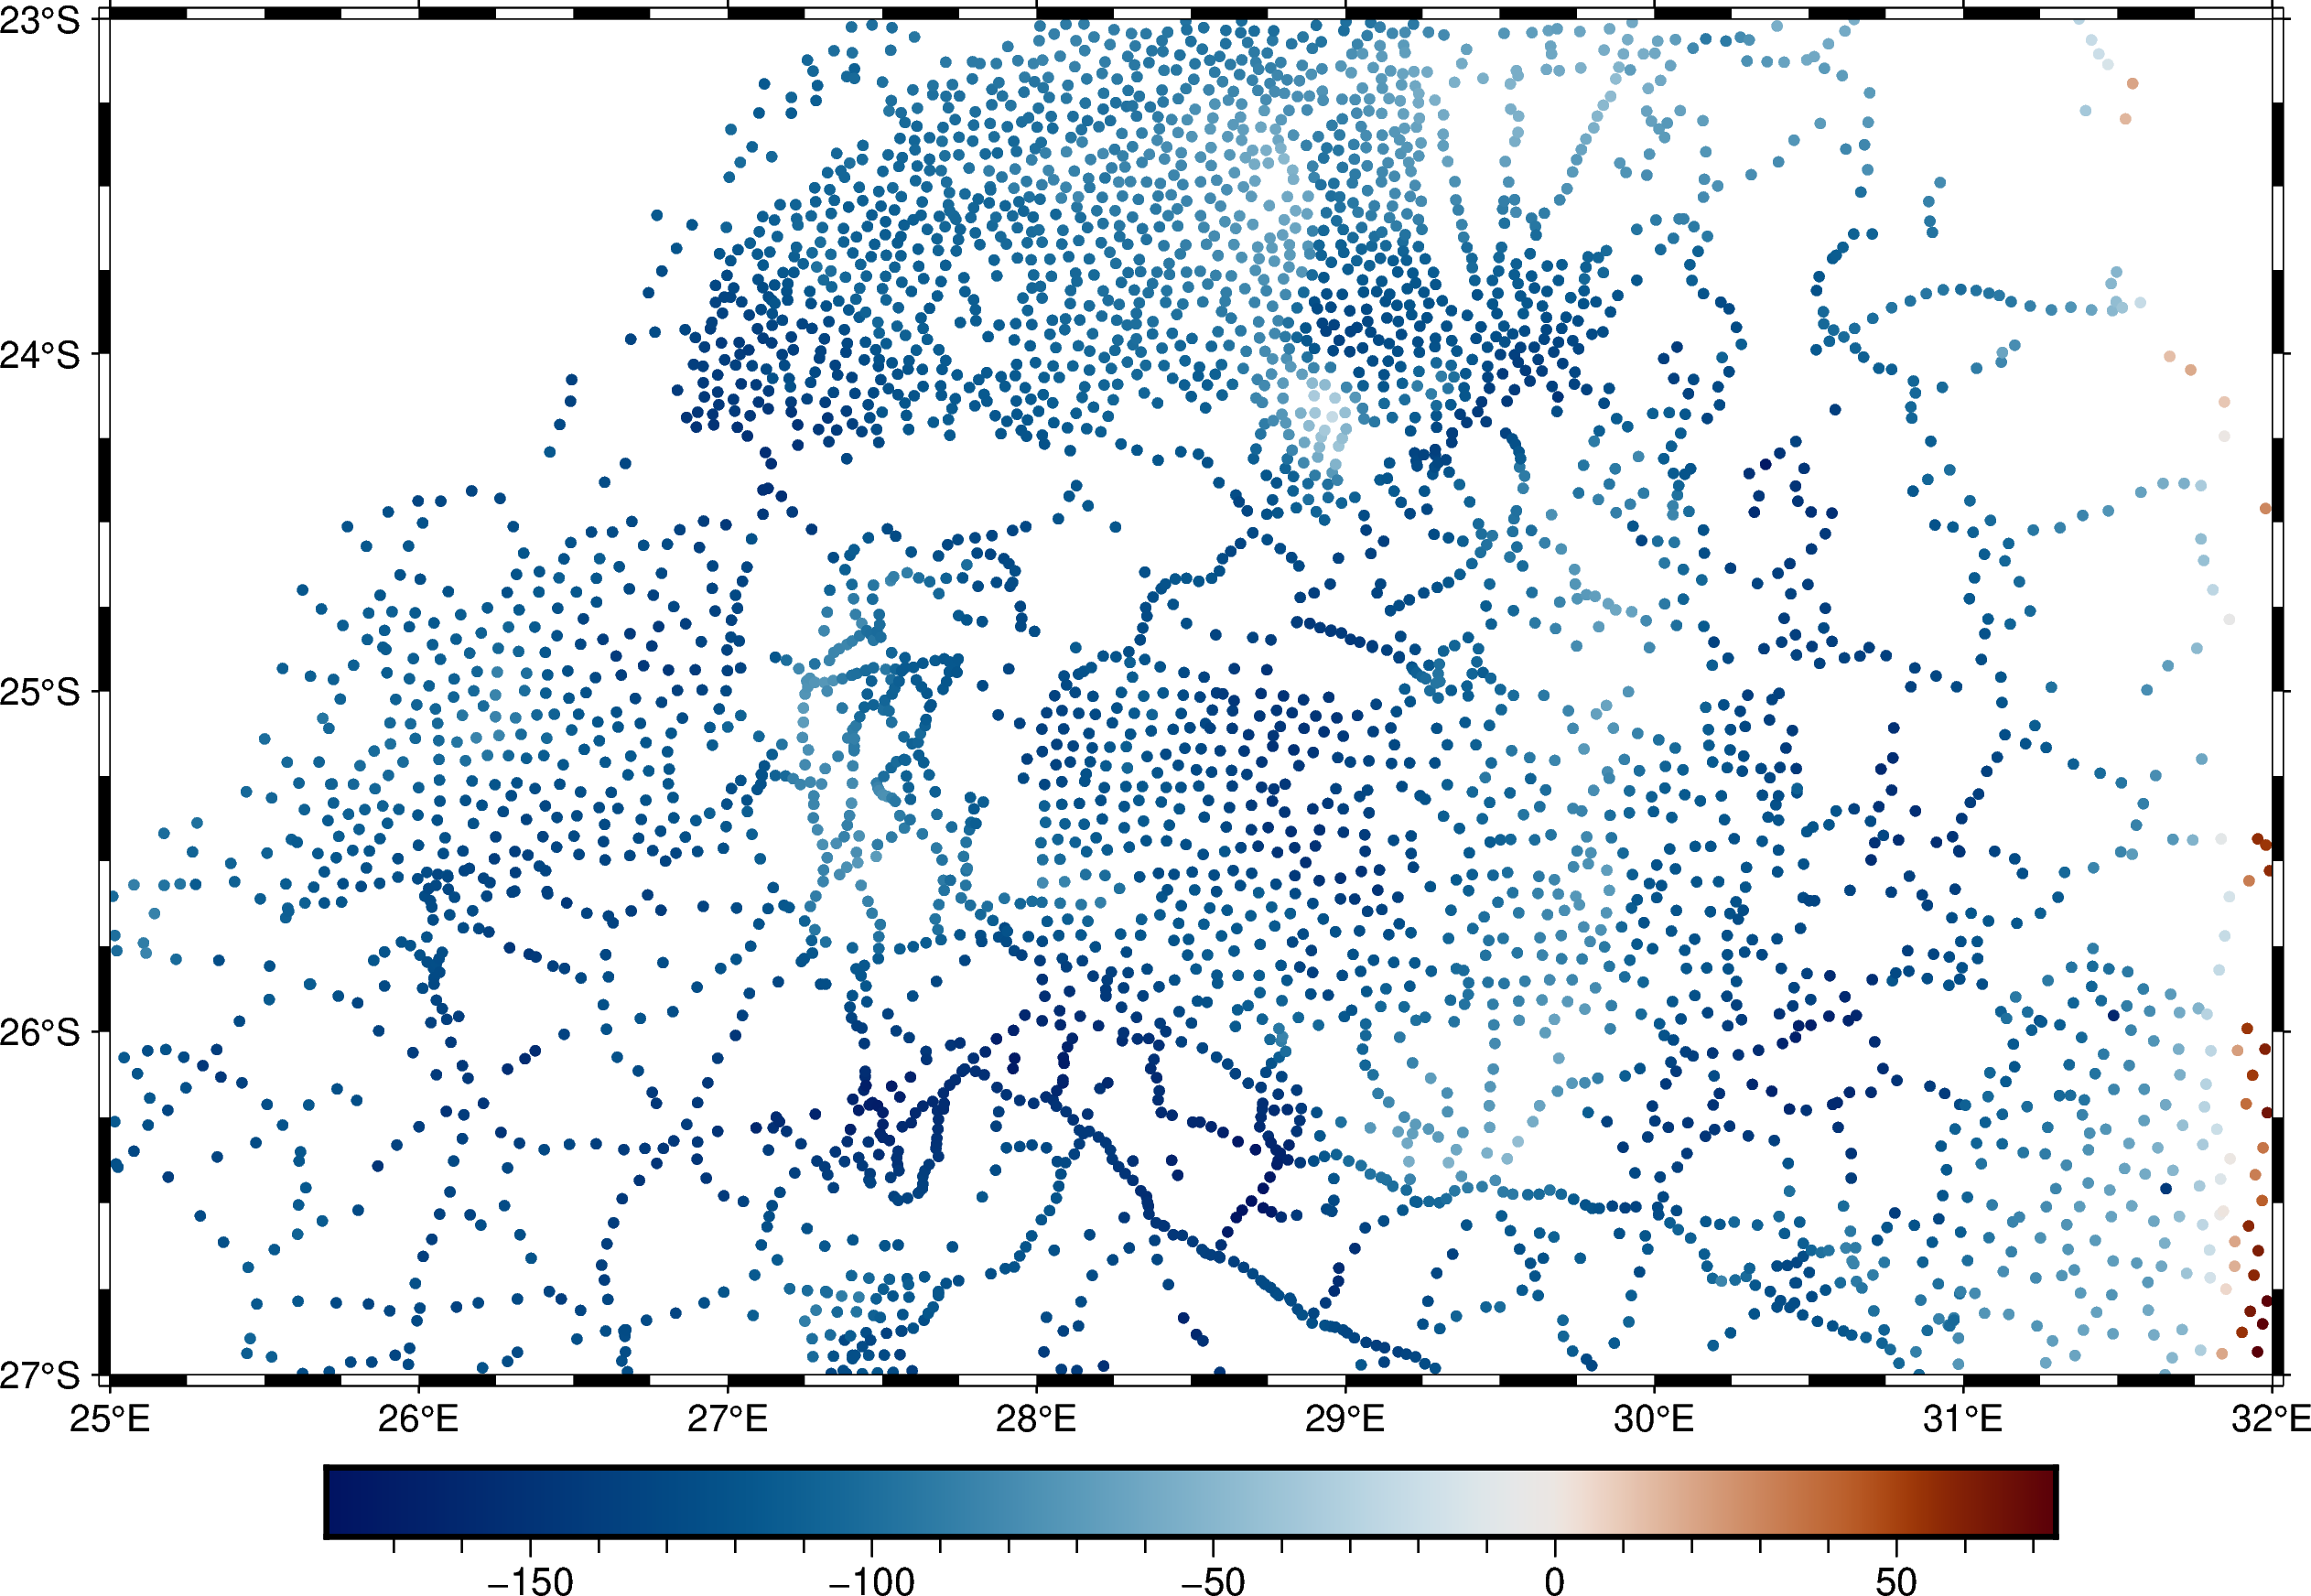

In [82]:
fig = pygmt.Figure()
pygmt.makecpt(cmap='vik+h', series=[dado.disturbio_bouguer_mgal.min(), dado.disturbio_bouguer_mgal.max()],)
fig.plot(
    x=dado.longitude,
    y=dado.latitude,
    fill=dado.disturbio_bouguer_mgal,
    style='c0.1c',
    projection="M20c",
    cmap=True,
    frame=True
)
fig.colorbar(frame=True)
fig.show(width=1000)

In [84]:
proj = pyproj.Proj(proj='merc', lat_ts=dado.latitude.mean())
dado['leste_m'], dado['norte_m'] = proj(dado.longitude, dado.latitude)
dado

,longitude,latitude,height_sea_level_m,gravity_mgal,geoide_m,altura_geometrica_m,gravidade_normal_mgal,disturbio_mgal,disturbio_bouguer_mgal,leste_m,norte_m
8648,25.01500,-26.26334,1230.2,978681.38,27.44,1257.64,978656.247360,25.132640,-115.683746,2.526066e+06,-2.733052e+06
8649,25.01932,-26.38713,1297.0,978669.02,27.84,1324.84,978644.399827,24.620173,-123.720514,2.526503e+06,-2.746924e+06
8650,25.02499,-26.39667,1304.8,978669.28,27.84,1332.64,978642.679408,26.600592,-122.613451,2.527075e+06,-2.747994e+06
8651,25.04500,-26.07668,1165.2,978681.08,26.96,1192.16,978663.108880,17.971120,-115.513553,2.529096e+06,-2.712163e+06
8652,25.07668,-26.35001,1262.5,978665.19,27.74,1290.24,978652.406949,12.783051,-131.683517,2.532295e+06,-2.742763e+06
...,...,...,...,...,...,...,...,...,...,...,...
12974,31.51500,-23.86333,300.5,978776.85,12.22,312.72,978781.630953,-4.780953,-39.795822,3.182450e+06,-2.466945e+06
12975,31.52499,-23.30000,280.7,978798.55,11.88,292.58,978750.570147,47.979853,15.220034,3.183459e+06,-2.405224e+06
12976,31.54832,-23.19333,245.7,978803.55,11.88,257.58,978754.392140,49.157860,20.316948,3.185814e+06,-2.393567e+06
12977,31.57333,-23.84833,226.8,978808.44,12.54,239.34,978803.279593,5.160407,-21.638195,3.188340e+06,-2.465298e+06


In [100]:
moho = vd.Trend(degree=3)
moho.fit((dado.leste_m, dado.norte_m), dado.disturbio_bouguer_mgal)
dado['regional_mgal'] = moho.predict((dado.leste_m, dado.norte_m))
dado

,longitude,latitude,height_sea_level_m,gravity_mgal,geoide_m,altura_geometrica_m,gravidade_normal_mgal,disturbio_mgal,disturbio_bouguer_mgal,leste_m,norte_m,regional_mgal
8648,25.01500,-26.26334,1230.2,978681.38,27.44,1257.64,978656.247360,25.132640,-115.683746,2.526066e+06,-2.733052e+06,-130.324034
8649,25.01932,-26.38713,1297.0,978669.02,27.84,1324.84,978644.399827,24.620173,-123.720514,2.526503e+06,-2.746924e+06,-130.938100
8650,25.02499,-26.39667,1304.8,978669.28,27.84,1332.64,978642.679408,26.600592,-122.613451,2.527075e+06,-2.747994e+06,-130.905648
8651,25.04500,-26.07668,1165.2,978681.08,26.96,1192.16,978663.108880,17.971120,-115.513553,2.529096e+06,-2.712163e+06,-129.613512
8652,25.07668,-26.35001,1262.5,978665.19,27.74,1290.24,978652.406949,12.783051,-131.683517,2.532295e+06,-2.742763e+06,-129.562854
...,...,...,...,...,...,...,...,...,...,...,...,...
12974,31.51500,-23.86333,300.5,978776.85,12.22,312.72,978781.630953,-4.780953,-39.795822,3.182450e+06,-2.466945e+06,-69.087630
12975,31.52499,-23.30000,280.7,978798.55,11.88,292.58,978750.570147,47.979853,15.220034,3.183459e+06,-2.405224e+06,-41.383471
12976,31.54832,-23.19333,245.7,978803.55,11.88,257.58,978754.392140,49.157860,20.316948,3.185814e+06,-2.393567e+06,-33.835190
12977,31.57333,-23.84833,226.8,978808.44,12.54,239.34,978803.279593,5.160407,-21.638195,3.188340e+06,-2.465298e+06,-66.519835


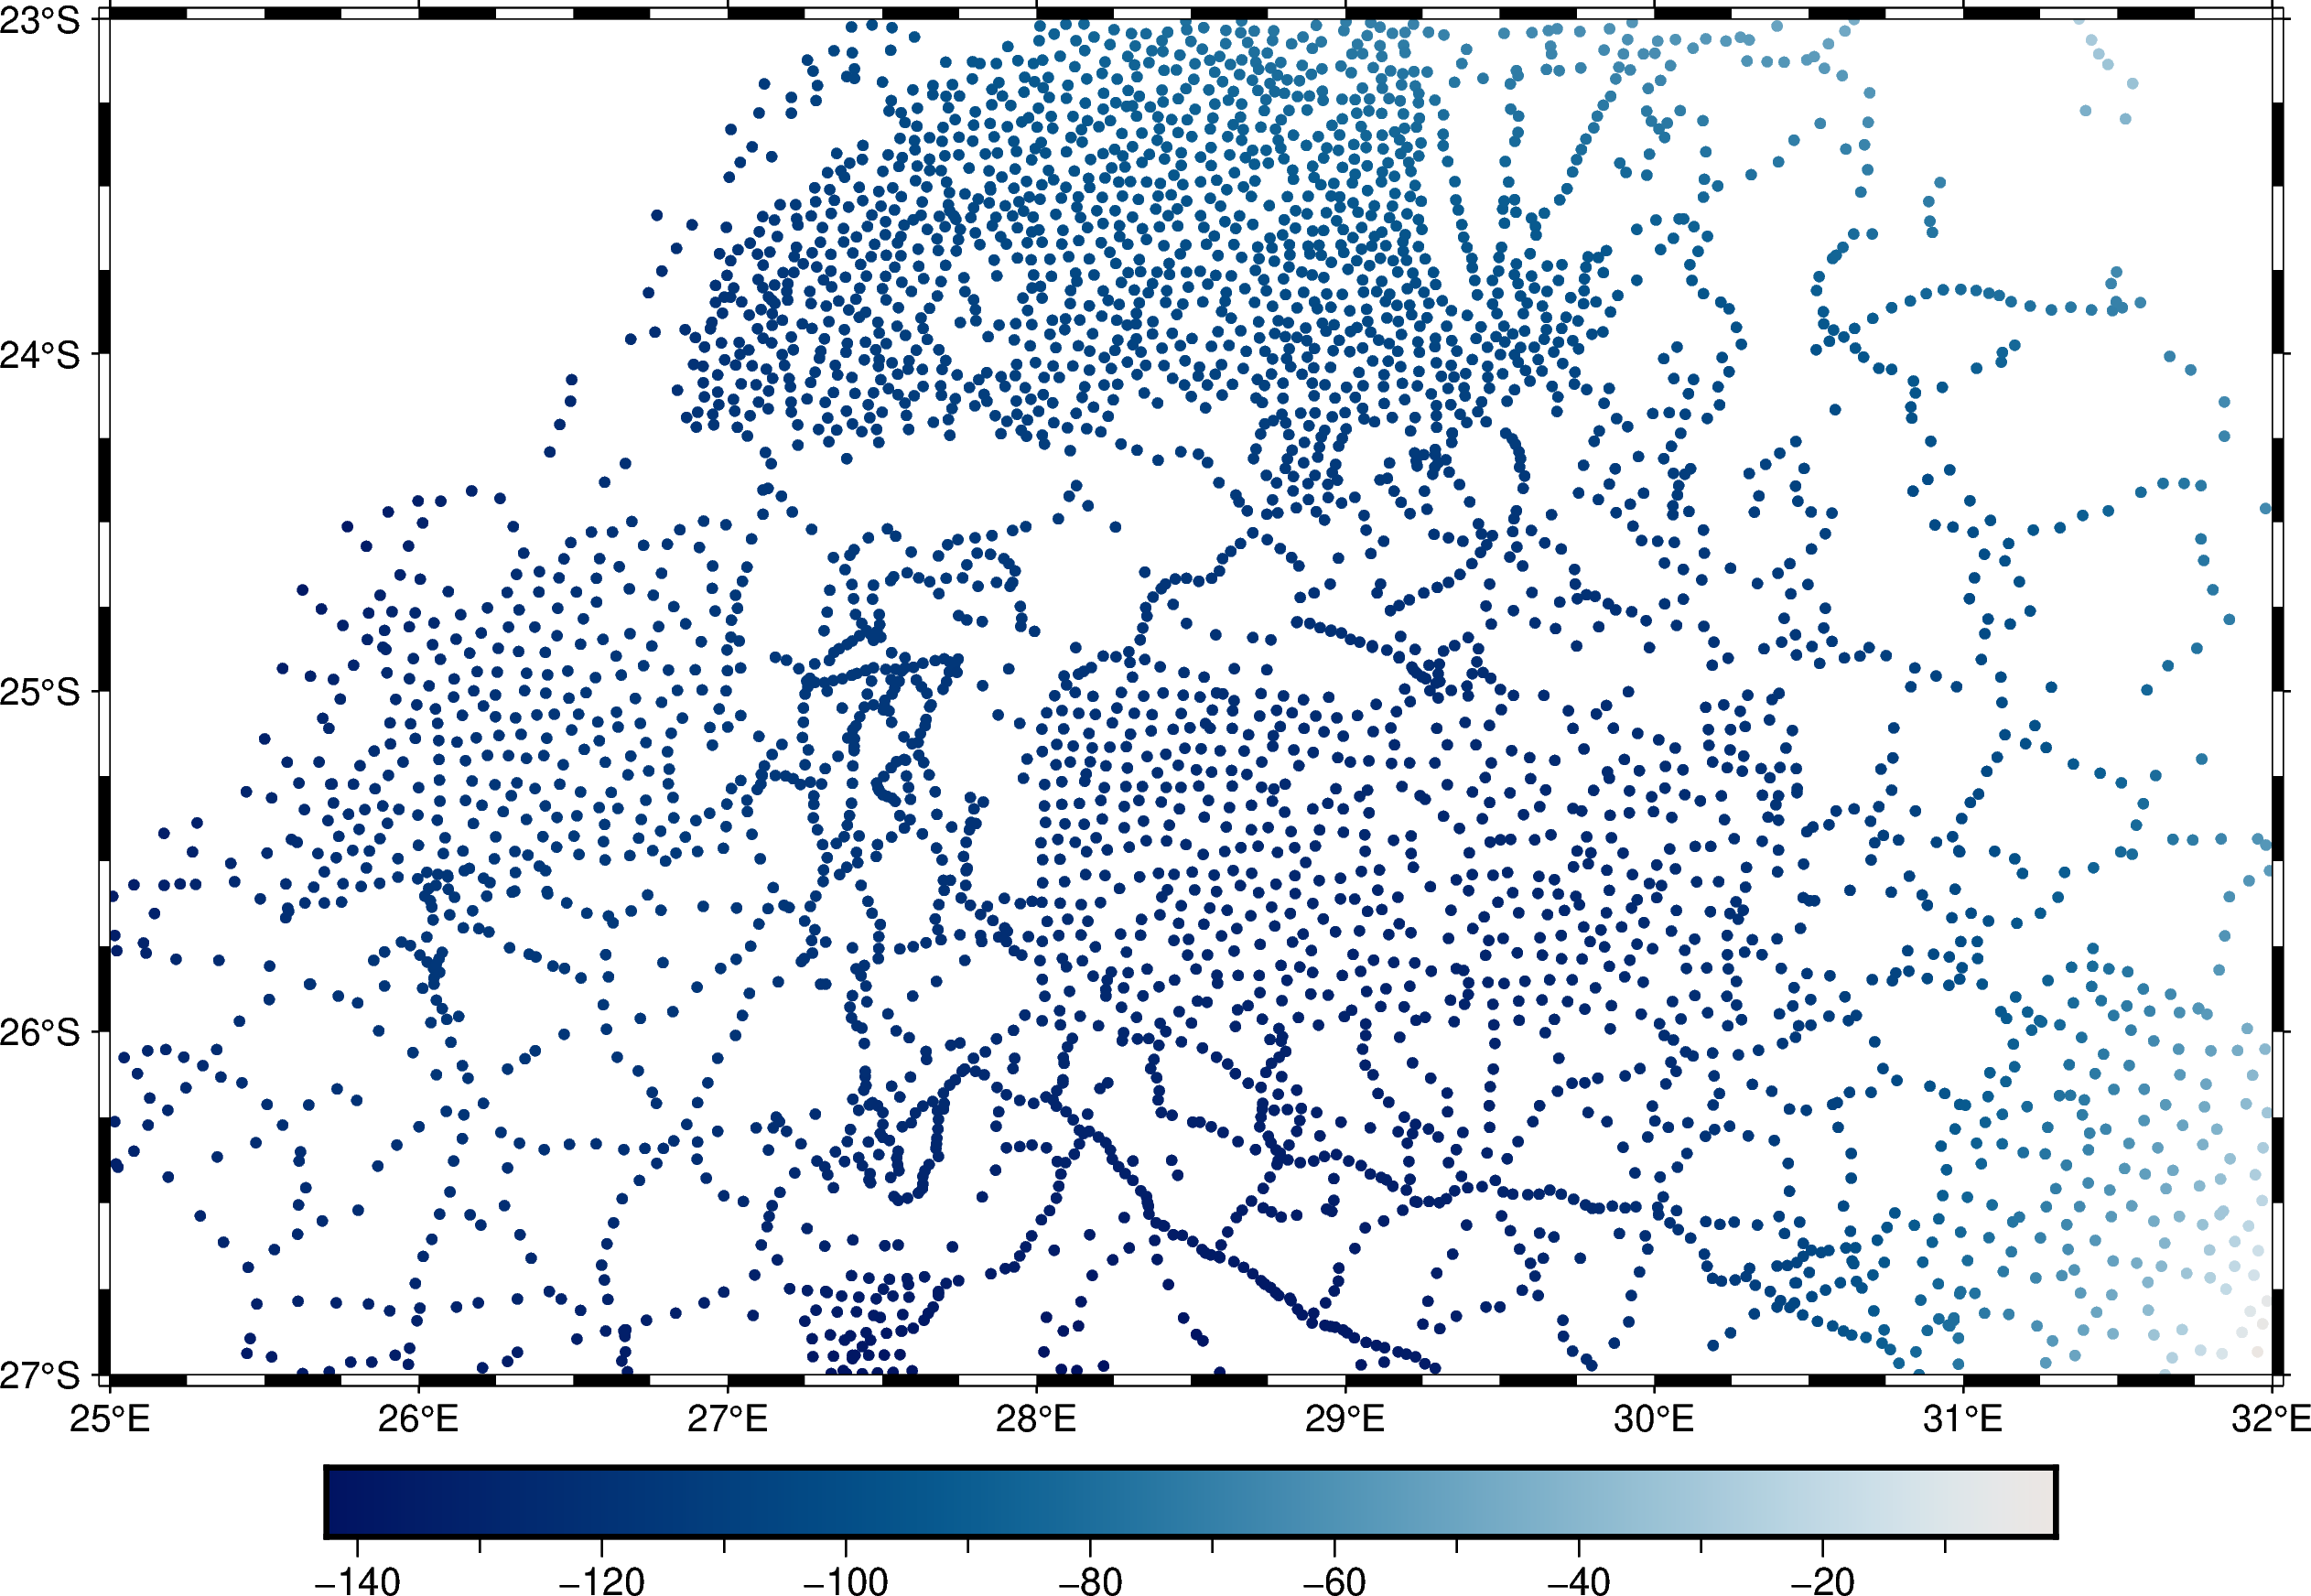

In [101]:
fig = pygmt.Figure()
pygmt.makecpt(cmap='vik+h', series=[dado.regional_mgal.min(), dado.regional_mgal.max()],)
fig.plot(
    x=dado.longitude,
    y=dado.latitude,
    fill=dado.regional_mgal,
    style='c0.1c',
    projection="M20c",
    cmap=True,
    frame=True
)
fig.colorbar(frame=True)
fig.show(width=1000)

In [102]:
dado['residual_mgal'] = dado.disturbio_bouguer_mgal - dado.regional_mgal

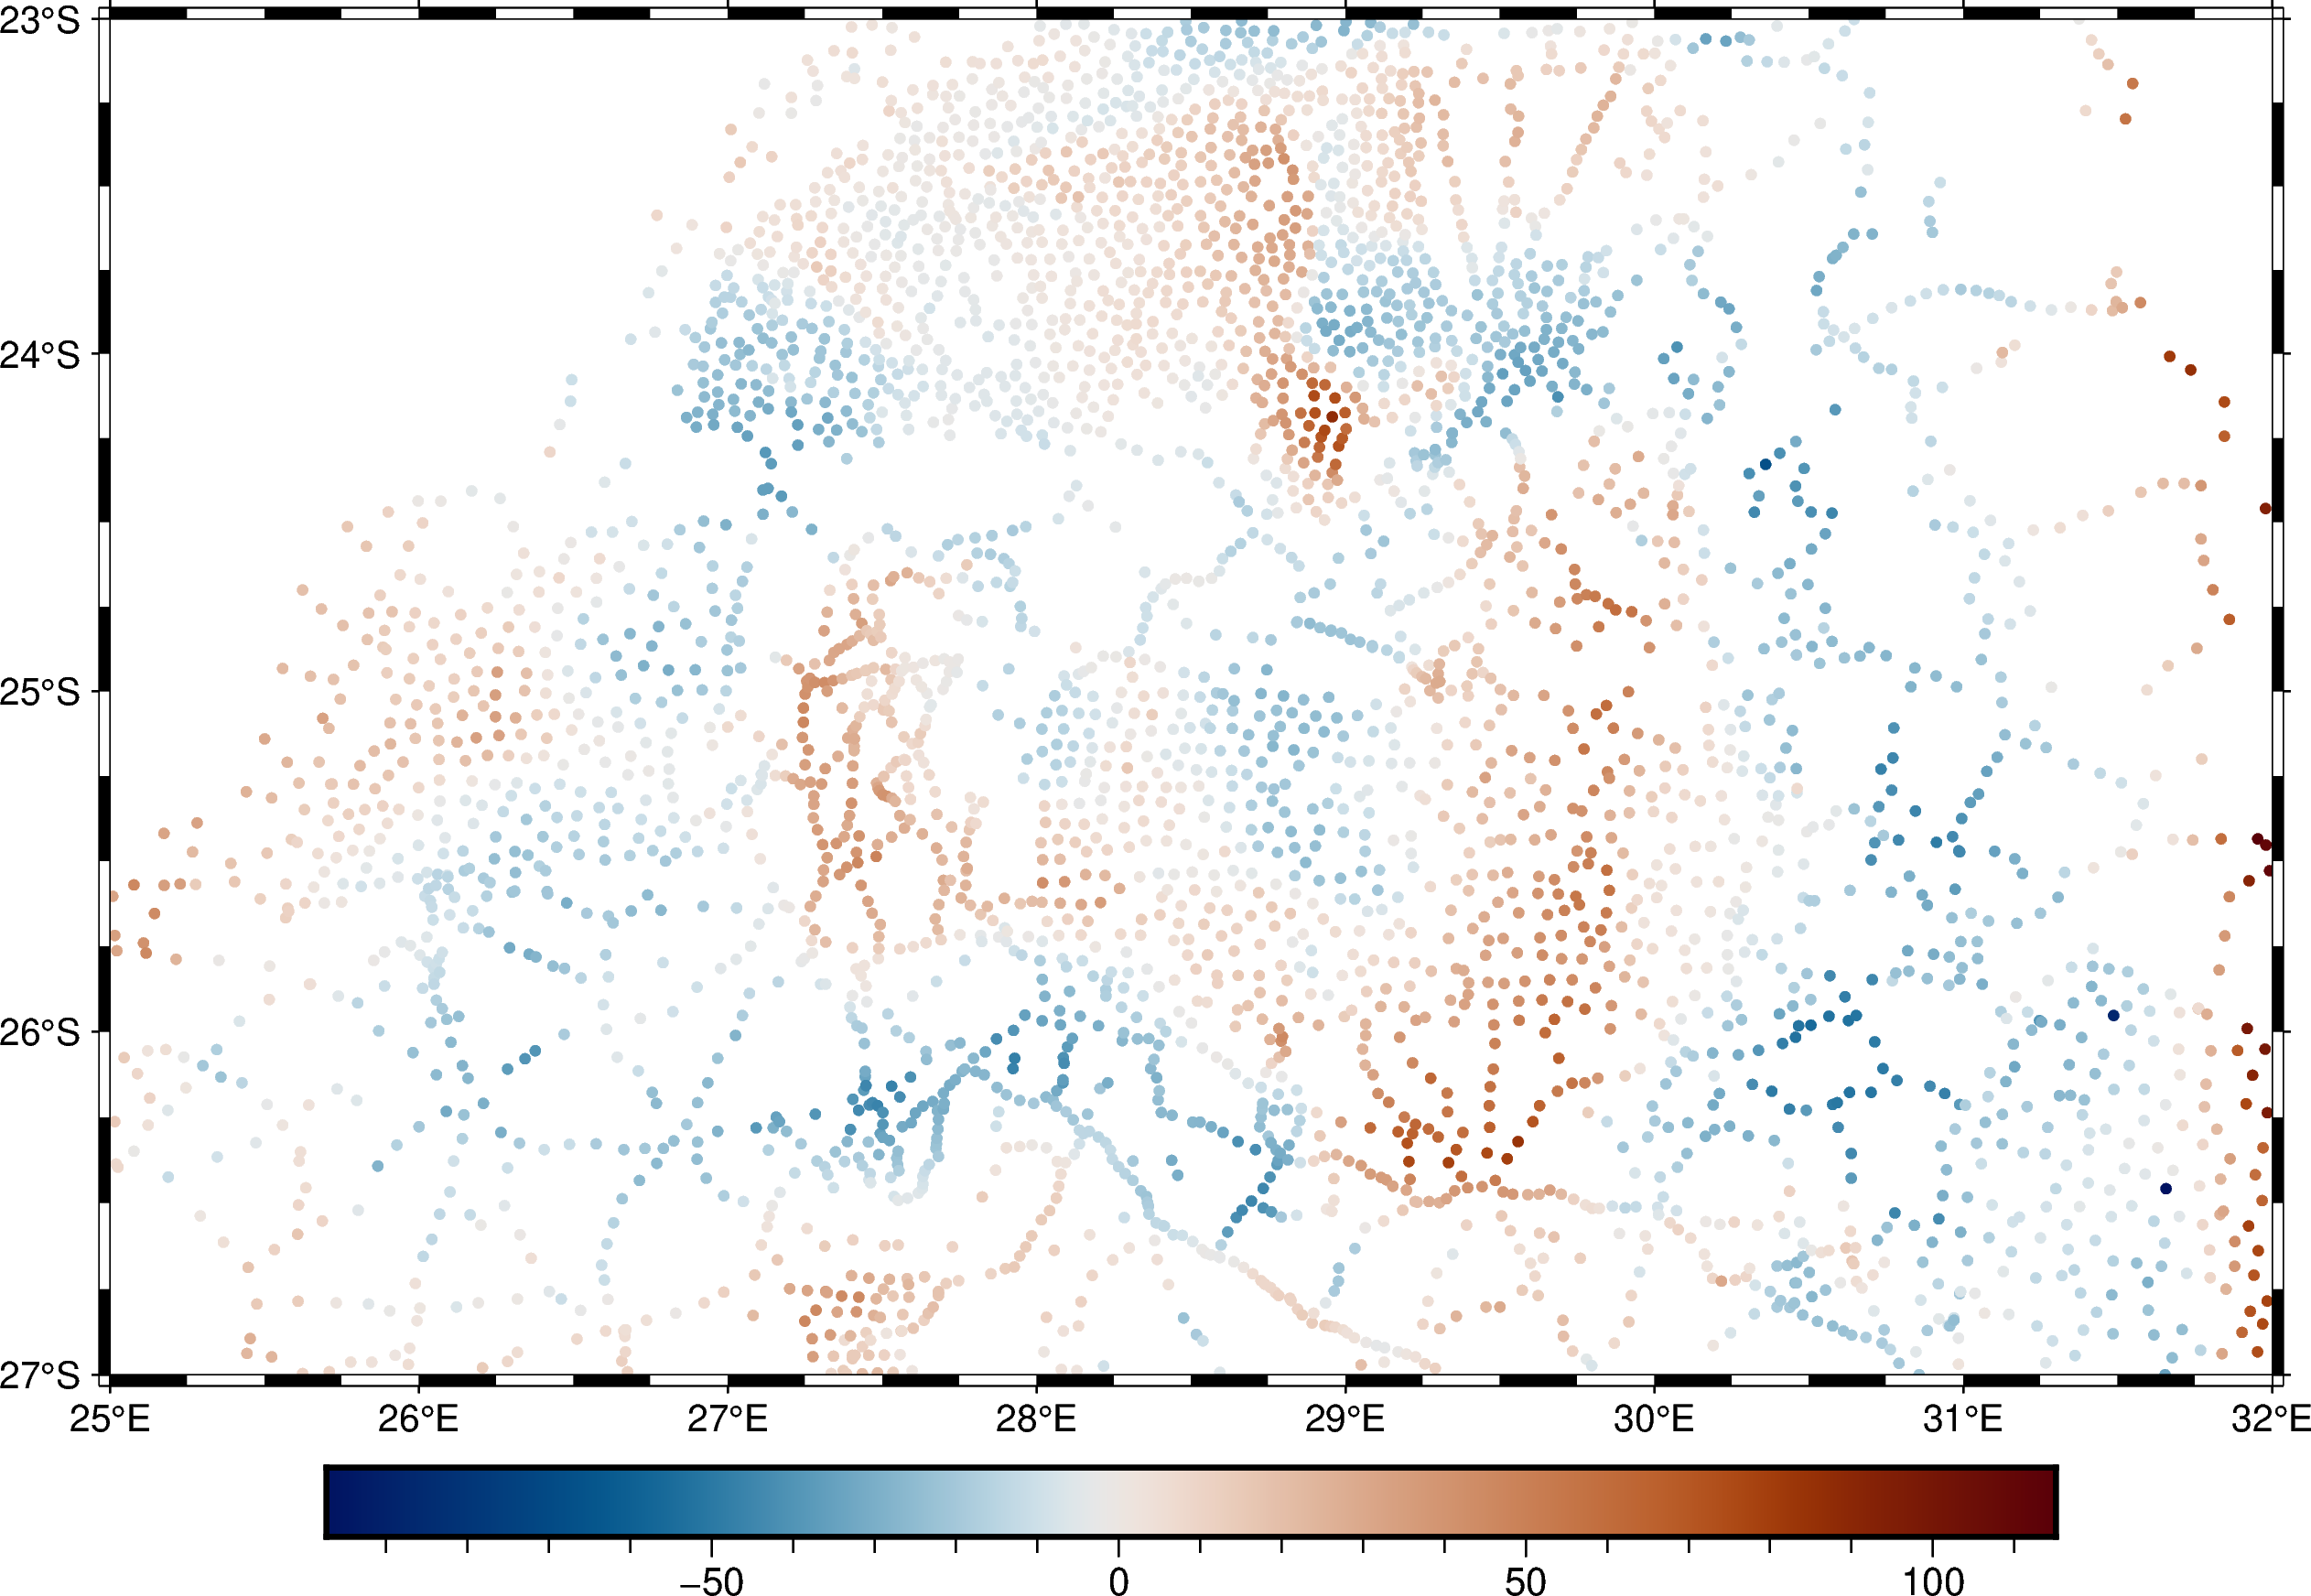

In [103]:
fig = pygmt.Figure()
pygmt.makecpt(cmap='vik+h', series=[dado.residual_mgal.min(), dado.residual_mgal.max()],)
fig.plot(
    x=dado.longitude,
    y=dado.latitude,
    fill=dado.residual_mgal,
    style='c0.1c',
    projection="M20c",
    cmap=True,
    frame=True
)
fig.colorbar(frame=True)
fig.show(width=1000)

In [104]:
eqs = hm.EquivalentSources(damping=1e-5, depth=5000)
eqs.fit((dado.leste_m, dado.norte_m, dado.altura_geometrica_m), dado.residual_mgal)

,damping,1e-05
,depth,5000
,points,None
,block_size,None
,parallel,True
,dtype,'float64'
Name,Type,Value
coefs_,"ndarray[float64](3877,)","[ 66274.01,-108261.75, 159965.92,..., 214882.28, 137474.45, -61390.23]"
depth_,int,5000
points_,tuple,"(array([252606...shape=(3877,)), array([-27330...shape=(3877,)), array([-3742....shape=(3877,)))"
region_,tuple,"(2525365.525571419, 3230584.8803728633, -2815825.4374932116, -2372463.1178860995)"


In [107]:
malha = eqs.grid(
    bd.grid_coordinates(
        regiao, spacing=1 / 60, non_dimensional_coords=10000
    ),
    dims=('latitude', 'longitude'),
    projection=proj        
)
malha

<xarray.Dataset> Size: 2MB
Dimensions:    (latitude: 241, longitude: 421)
Coordinates:
  * latitude   (latitude) float64 2kB -27.0 -26.98 -26.97 ... -23.02 -23.0
  * longitude  (longitude) float64 3kB 25.0 25.02 25.03 ... 31.97 31.98 32.0
    upward     (latitude, longitude) float64 812kB 1e+04 1e+04 ... 1e+04 1e+04
Data variables:
    scalars    (latitude, longitude) float64 812kB 4.236 4.331 ... 9.019 8.922
Attributes:
    metadata:  Generated by EquivalentSources(damping=1e-05, depth=5000)

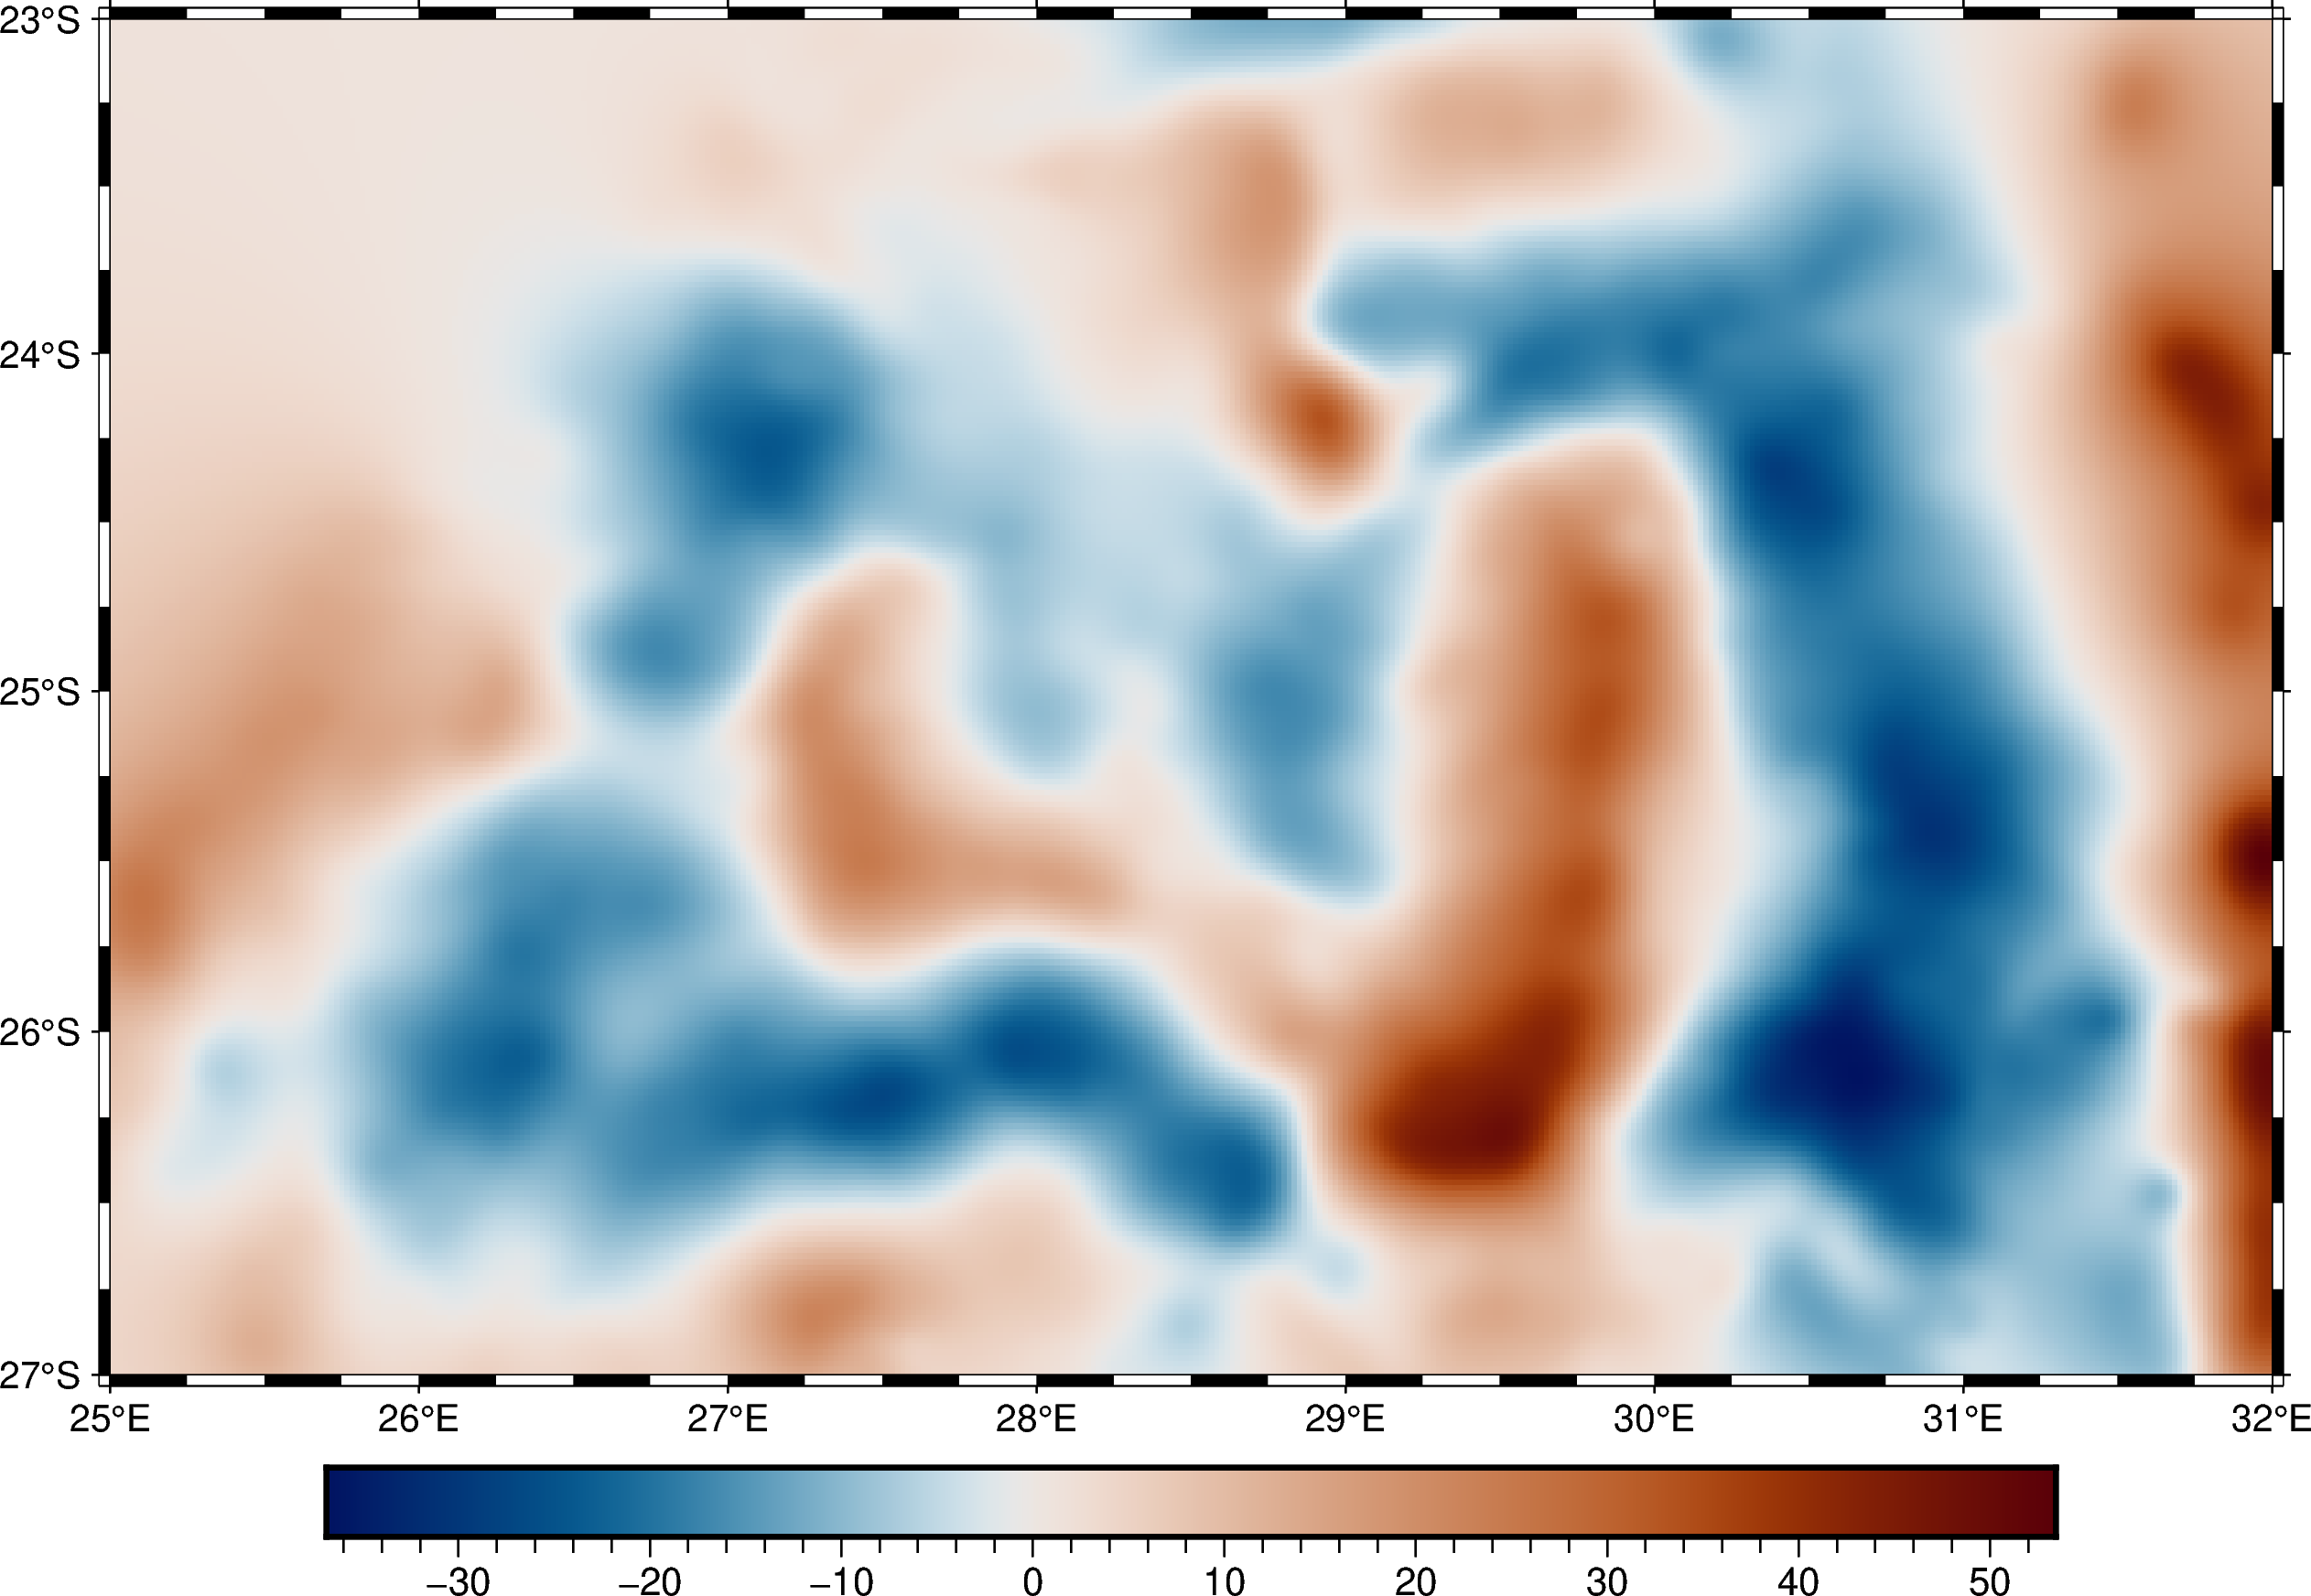

In [108]:
fig = pygmt.Figure()
fig.grdimage(malha.scalars, cmap="vik+h", projection="M20c", frame=True)
fig.colorbar()
fig.show(width=1000)